### Agglomerative Clustering

- Single Linkage - minimum of all pairwise distances between clusters
- Complete Linkage - maximum of all pairwise distances between clusters
- Average Linkage - average of all pairwise distances between clusters

1D data points  
single linkage  
Show the updated proximity matrix after every iteration 


Initial Proximity Matrix:
      18    22    25    27    42    43
18   0.0   4.0   7.0   9.0  24.0  25.0
22   4.0   0.0   3.0   5.0  20.0  21.0
25   7.0   3.0   0.0   2.0  17.0  18.0
27   9.0   5.0   2.0   0.0  15.0  16.0
42  24.0  20.0  17.0  15.0   0.0   1.0
43  25.0  21.0  18.0  16.0   1.0   0.0

Single - Iteration 1
Merge: [np.int64(42)] and [np.int64(43)]
Distance = 1
Updated Proximity Matrix:
         {18}  {22}  {25}  {27}  {42,43}
{18}      0.0   4.0   7.0   9.0     24.0
{22}      4.0   0.0   3.0   5.0     20.0
{25}      7.0   3.0   0.0   2.0     17.0
{27}      9.0   5.0   2.0   0.0     15.0
{42,43}  24.0  20.0  17.0  15.0      0.0

Single - Iteration 2
Merge: [np.int64(25)] and [np.int64(27)]
Distance = 2
Updated Proximity Matrix:
         {18}  {22}  {42,43}  {25,27}
{18}      0.0   4.0     24.0      7.0
{22}      4.0   0.0     20.0      3.0
{42,43}  24.0  20.0      0.0     15.0
{25,27}   7.0   3.0     15.0      0.0

Single - Iteration 3
Merge: [np.int64(22)] and [np.int64(25)

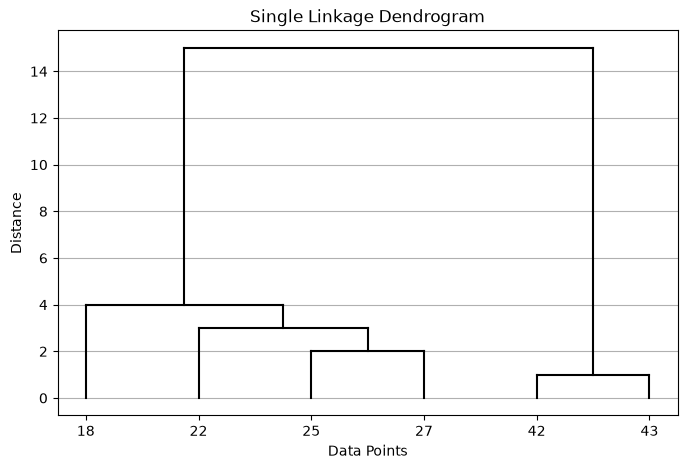


Complete - Iteration 1
Merge: [np.int64(42)] and [np.int64(43)]
Distance = 1
Updated Proximity Matrix:
         {18}  {22}  {25}  {27}  {42,43}
{18}      0.0   4.0   7.0   9.0     25.0
{22}      4.0   0.0   3.0   5.0     21.0
{25}      7.0   3.0   0.0   2.0     18.0
{27}      9.0   5.0   2.0   0.0     16.0
{42,43}  25.0  21.0  18.0  16.0      0.0

Complete - Iteration 2
Merge: [np.int64(25)] and [np.int64(27)]
Distance = 2
Updated Proximity Matrix:
         {18}  {22}  {42,43}  {25,27}
{18}      0.0   4.0     25.0      9.0
{22}      4.0   0.0     21.0      5.0
{42,43}  25.0  21.0      0.0     18.0
{25,27}   9.0   5.0     18.0      0.0

Complete - Iteration 3
Merge: [np.int64(18)] and [np.int64(22)]
Distance = 4
Updated Proximity Matrix:
         {42,43}  {25,27}  {18,22}
{42,43}      0.0     18.0     25.0
{25,27}     18.0      0.0      9.0
{18,22}     25.0      9.0      0.0

Complete - Iteration 4
Merge: [np.int64(25), np.int64(27)] and [np.int64(18), np.int64(22)]
Distance = 9
Update

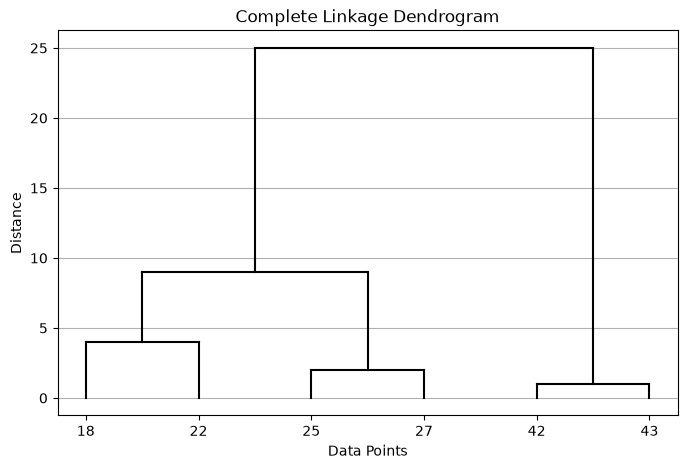


Average - Iteration 1
Merge: [np.int64(42)] and [np.int64(43)]
Distance = 1.0
Updated Proximity Matrix:
         {18}  {22}  {25}  {27}  {42,43}
{18}      0.0   4.0   7.0   9.0     24.5
{22}      4.0   0.0   3.0   5.0     20.5
{25}      7.0   3.0   0.0   2.0     17.5
{27}      9.0   5.0   2.0   0.0     15.5
{42,43}  24.5  20.5  17.5  15.5      0.0

Average - Iteration 2
Merge: [np.int64(25)] and [np.int64(27)]
Distance = 2.0
Updated Proximity Matrix:
         {18}  {22}  {42,43}  {25,27}
{18}      0.0   4.0     24.5      8.0
{22}      4.0   0.0     20.5      4.0
{42,43}  24.5  20.5      0.0     16.5
{25,27}   8.0   4.0     16.5      0.0

Average - Iteration 3
Merge: [np.int64(18)] and [np.int64(22)]
Distance = 4.0
Updated Proximity Matrix:
         {42,43}  {25,27}  {18,22}
{42,43}      0.0     16.5     22.5
{25,27}     16.5      0.0      6.0
{18,22}     22.5      6.0      0.0

Average - Iteration 4
Merge: [np.int64(25), np.int64(27)] and [np.int64(18), np.int64(22)]
Distance = 6.0
Up

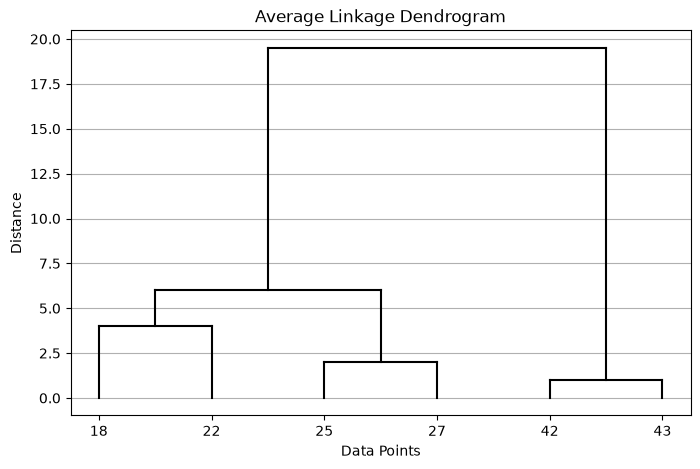

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data
data = np.array([18, 22, 25, 27, 42, 43])

points = data.copy()


# Step 1: Distance between two points
def get_distance(a, b):
    return abs(a - b)


# Step 2: Initial proximity matrix
def get_distance_matrix(data):
    n = len(data)
    D = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            D[i, j] = get_distance(data[i], data[j])

    return D


D = get_distance_matrix(data)

print("Initial Proximity Matrix:")
print(pd.DataFrame(D, index=points, columns=points))


# Step 3: Hierarchical clustering
def hierarchical_clustering(data, points, method='single'):

    clusters = [[i] for i in range(len(data))]
    merges = []

    heights = {tuple(c): 0 for c in clusters}
    positions = {tuple(c): float(c[0]) for c in clusters}

    def cluster_distance(c1, c2):
        distances = [
            get_distance(data[a], data[b])
            for a in c1 for b in c2
        ]

        if method == 'single':
            return min(distances)
        elif method == 'complete':
            return max(distances)
        else:
            return np.mean(distances)

    iteration = 1

    while len(clusters) > 1:
        min_dist = float('inf')
        merge_i, merge_j = -1, -1

        # Find closest clusters
        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                distance = cluster_distance(clusters[i], clusters[j])

                if distance < min_dist:
                    min_dist = distance
                    merge_i, merge_j = i, j

        c1 = clusters[merge_i]
        c2 = clusters[merge_j]

        print(f"\n{method.capitalize()} - Iteration {iteration}")
        print("Merge:", [points[i] for i in c1],
              "and", [points[i] for i in c2])
        print("Distance =", min_dist)

        merges.append((c1.copy(), c2.copy(), min_dist))

        # Merge clusters
        merged = c1 + c2

        clusters.pop(merge_j)
        clusters.pop(merge_i)
        clusters.append(merged)

        # Store dendrogram height and position
        heights[tuple(merged)] = min_dist
        positions[tuple(merged)] = (
            positions[tuple(c1)] + positions[tuple(c2)]
        ) / 2

        # Updated proximity matrix
        n = len(clusters)
        new_D = np.zeros((n, n))

        for i in range(n):
            for j in range(n):
                if i != j:
                    new_D[i, j] = cluster_distance(
                        clusters[i], clusters[j]
                    )

        labels = []
        for c in clusters:
            label = ""
            for k in c:
                label += str(points[k]) + ","
            labels.append("{" + label[:-1] + "}")

        print("Updated Proximity Matrix:")
        print(pd.DataFrame(
            new_D, index=labels, columns=labels
        ))

        iteration += 1

    # Step 4: Draw dendrogram
    plt.figure(figsize=(8, 5))

    for c1, c2, height in merges:
        x1 = positions[tuple(c1)]
        x2 = positions[tuple(c2)]

        h1 = heights[tuple(c1)]
        h2 = heights[tuple(c2)]

        plt.plot([x1, x1], [h1, height], color='black')
        plt.plot([x2, x2], [h2, height], color='black')
        plt.plot([x1, x2], [height, height], color='black')

    plt.xticks(range(len(points)), points)
    plt.xlabel("Data Points")
    plt.ylabel("Distance")
    plt.title(f"{method.capitalize()} Linkage Dendrogram")
    plt.grid(axis='y')
    plt.show()


# Run single linkage (or complete / average)
for method in ['single', 'complete', 'average']:
    hierarchical_clustering(data, points, method)

2D points, Single, complete and average linkages  
proximity matrix using Euclidean distance


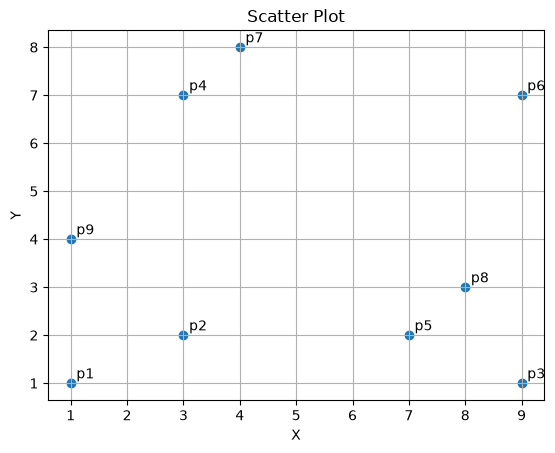

Initial Proximity Matrix
       p1    p2    p3    p4    p5     p6    p7    p8    p9
p1   0.00  2.24  8.00  6.32  6.08  10.00  7.62  7.28  3.00
p2   2.24  0.00  6.08  5.00  4.00   7.81  6.08  5.10  2.83
p3   8.00  6.08  0.00  8.49  2.24   6.00  8.60  2.24  8.54
p4   6.32  5.00  8.49  0.00  6.40   6.00  1.41  6.40  3.61
p5   6.08  4.00  2.24  6.40  0.00   5.39  6.71  1.41  6.32
p6  10.00  7.81  6.00  6.00  5.39   0.00  5.10  4.12  8.54
p7   7.62  6.08  8.60  1.41  6.71   5.10  0.00  6.40  5.00
p8   7.28  5.10  2.24  6.40  1.41   4.12  6.40  0.00  7.07
p9   3.00  2.83  8.54  3.61  6.32   8.54  5.00  7.07  0.00

Single Linkage - Iteration 1
Merge: ['p4'] and ['p7']
Distance = 1.414
Updated Proximity Matrix:
          {p1}  {p2}  {p3}  {p5}   {p6}  {p8}  {p9}  {p4,p7}
{p1}      0.00  2.24  8.00  6.08  10.00  7.28  3.00     6.32
{p2}      2.24  0.00  6.08  4.00   7.81  5.10  2.83     5.00
{p3}      8.00  6.08  0.00  2.24   6.00  2.24  8.54     8.49
{p5}      6.08  4.00  2.24  0.00   5.39  1.

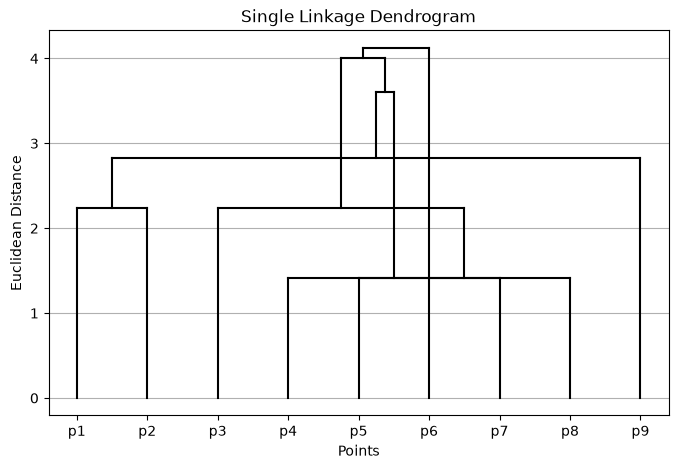


Complete Linkage - Iteration 1
Merge: ['p4'] and ['p7']
Distance = 1.414
Updated Proximity Matrix:
          {p1}  {p2}  {p3}  {p5}   {p6}  {p8}  {p9}  {p4,p7}
{p1}      0.00  2.24  8.00  6.08  10.00  7.28  3.00     7.62
{p2}      2.24  0.00  6.08  4.00   7.81  5.10  2.83     6.08
{p3}      8.00  6.08  0.00  2.24   6.00  2.24  8.54     8.60
{p5}      6.08  4.00  2.24  0.00   5.39  1.41  6.32     6.71
{p6}     10.00  7.81  6.00  5.39   0.00  4.12  8.54     6.00
{p8}      7.28  5.10  2.24  1.41   4.12  0.00  7.07     6.40
{p9}      3.00  2.83  8.54  6.32   8.54  7.07  0.00     5.00
{p4,p7}   7.62  6.08  8.60  6.71   6.00  6.40  5.00     0.00

Complete Linkage - Iteration 2
Merge: ['p5'] and ['p8']
Distance = 1.414
Updated Proximity Matrix:
          {p1}  {p2}  {p3}   {p6}  {p9}  {p4,p7}  {p5,p8}
{p1}      0.00  2.24  8.00  10.00  3.00     7.62     7.28
{p2}      2.24  0.00  6.08   7.81  2.83     6.08     5.10
{p3}      8.00  6.08  0.00   6.00  8.54     8.60     2.24
{p6}     10.00  7.8

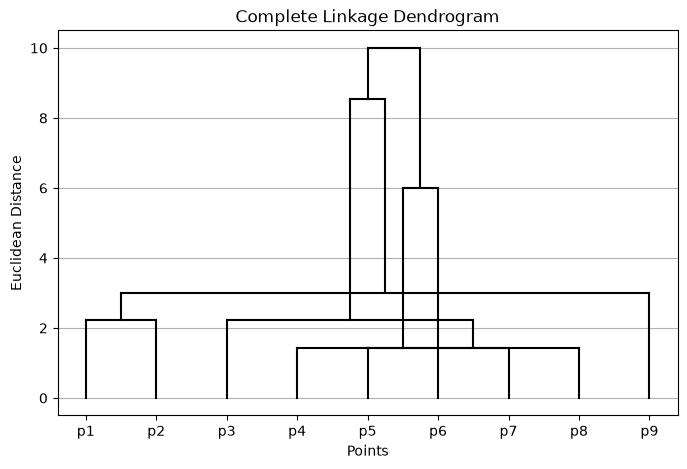


Average Linkage - Iteration 1
Merge: ['p4'] and ['p7']
Distance = 1.414
Updated Proximity Matrix:
          {p1}  {p2}  {p3}  {p5}   {p6}  {p8}  {p9}  {p4,p7}
{p1}      0.00  2.24  8.00  6.08  10.00  7.28  3.00     6.97
{p2}      2.24  0.00  6.08  4.00   7.81  5.10  2.83     5.54
{p3}      8.00  6.08  0.00  2.24   6.00  2.24  8.54     8.54
{p5}      6.08  4.00  2.24  0.00   5.39  1.41  6.32     6.56
{p6}     10.00  7.81  6.00  5.39   0.00  4.12  8.54     5.55
{p8}      7.28  5.10  2.24  1.41   4.12  0.00  7.07     6.40
{p9}      3.00  2.83  8.54  6.32   8.54  7.07  0.00     4.30
{p4,p7}   6.97  5.54  8.54  6.56   5.55  6.40  4.30     0.00

Average Linkage - Iteration 2
Merge: ['p5'] and ['p8']
Distance = 1.414
Updated Proximity Matrix:
          {p1}  {p2}  {p3}   {p6}  {p9}  {p4,p7}  {p5,p8}
{p1}      0.00  2.24  8.00  10.00  3.00     6.97     6.68
{p2}      2.24  0.00  6.08   7.81  2.83     5.54     4.55
{p3}      8.00  6.08  0.00   6.00  8.54     8.54     2.24
{p6}     10.00  7.81 

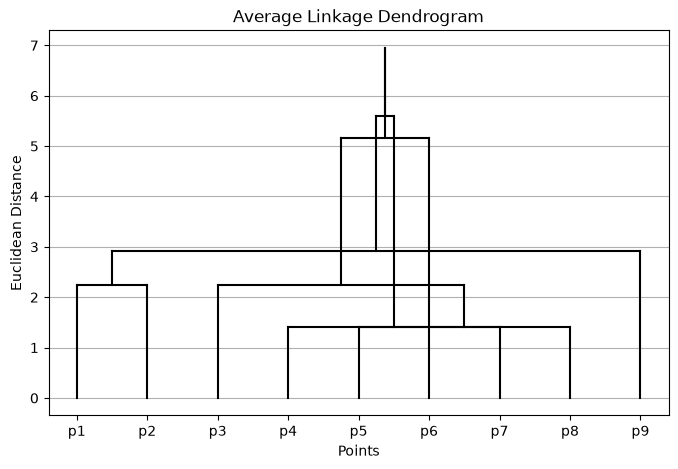

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data
df = pd.DataFrame({
    'Point': ['p1','p2','p3','p4','p5','p6','p7','p8','p9'],
    'X': [1,3,9,3,7,9,4,8,1],
    'Y': [1,2,1,7,2,7,8,3,4]
})

points = df['Point'].values
data = df[['X', 'Y']].values


# a. Scatter plot
plt.scatter(data[:, 0], data[:, 1])

for i, p in enumerate(points):
    plt.text(data[i, 0] + 0.1, data[i, 1] + 0.1, p)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Scatter Plot")
plt.grid(True)
plt.show()


# Initial proximity matrix using Euclidean distance
def get_distance_matrix(data):
    n = len(data)
    D = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            D[i, j] = np.sqrt(np.sum((data[i] - data[j]) ** 2))

    return D


D = get_distance_matrix(data)

print("Initial Proximity Matrix")
print(pd.DataFrame(D, index=points, columns=points).round(2))


# Hierarchical clustering
def hierarchical_clustering(data, points, method):
    clusters = [[i] for i in range(len(data))]
    merges = []

    heights = {tuple(c): 0 for c in clusters}
    positions = {tuple(c): float(c[0]) for c in clusters}

    def cluster_distance(c1, c2):
        distances = [
            np.sqrt(np.sum((data[a] - data[b]) ** 2))
            for a in c1 
            for b in c2
        ]

        if method == 'single':
            return min(distances)
        elif method == 'complete':
            return max(distances)
        else:
            return np.mean(distances)

    iteration = 1

    while len(clusters) > 1:
        min_dist = float('inf')
        merge_i, merge_j = -1, -1

        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                distance = cluster_distance(clusters[i], clusters[j])

                if distance < min_dist:
                    min_dist = distance
                    merge_i, merge_j = i, j

        c1 = clusters[merge_i]
        c2 = clusters[merge_j]

        print(f"\n{method} Linkage - Iteration {iteration}")
        print("Merge:", [points[i] for i in c1],"and", [points[i] for i in c2])
        print("Distance =", round(min_dist, 3))

        merges.append((c1.copy(), c2.copy(), min_dist))

        merged = c1 + c2

        clusters.pop(merge_j)
        clusters.pop(merge_i)
        clusters.append(merged)

        # Store height and simple midpoint
        heights[tuple(merged)] = min_dist
        positions[tuple(merged)] = (positions[tuple(c1)] + positions[tuple(c2)]) / 2

        # Updated proximity matrix
        n = len(clusters)
        new_D = np.zeros((n, n))

        for i in range(n):
            for j in range(n):
                if i != j:
                    new_D[i, j] = cluster_distance(clusters[i], clusters[j])

        labels = []
        for c in clusters:
            label = ""
            for k in c:
                label += points[k] + ","
            labels.append("{" + label[:-1] + "}")

        print("Updated Proximity Matrix:")
        print(pd.DataFrame(new_D, index=labels, columns=labels).round(2))

        iteration += 1

    # c. Draw dendrogram manually
    plt.figure(figsize=(8, 5))

    for c1, c2, height in merges:
        x1 = positions[tuple(c1)]
        x2 = positions[tuple(c2)]

        h1 = heights[tuple(c1)]
        h2 = heights[tuple(c2)]

        plt.plot([x1, x1], [h1, height], color='black')
        plt.plot([x2, x2], [h2, height], color='black')
        plt.plot([x1, x2], [height, height], color='black')

    plt.xticks(range(len(points)), points)
    plt.xlabel("Points")
    plt.ylabel("Euclidean Distance")
    plt.title(f"{method.capitalize()} Linkage Dendrogram")
    plt.grid(axis='y')
    plt.show()


for method in ['single', 'complete', 'average']:
    hierarchical_clustering(data, points, method)


2D points  
single, complete and average linkages  
manhattan, euclidean and minowski matrix

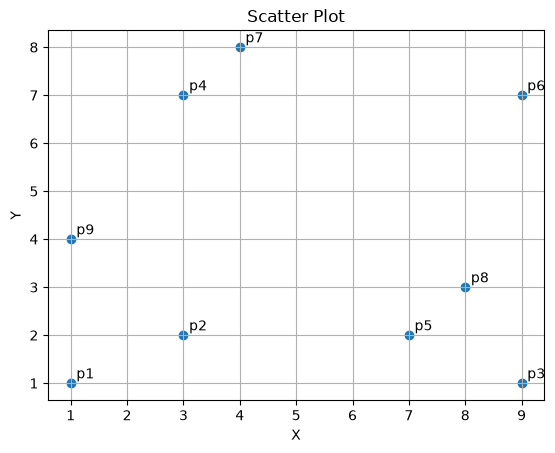


Euclidean Proximity Matrix
       p1    p2    p3    p4    p5     p6    p7    p8    p9
p1   0.00  2.24  8.00  6.32  6.08  10.00  7.62  7.28  3.00
p2   2.24  0.00  6.08  5.00  4.00   7.81  6.08  5.10  2.83
p3   8.00  6.08  0.00  8.49  2.24   6.00  8.60  2.24  8.54
p4   6.32  5.00  8.49  0.00  6.40   6.00  1.41  6.40  3.61
p5   6.08  4.00  2.24  6.40  0.00   5.39  6.71  1.41  6.32
p6  10.00  7.81  6.00  6.00  5.39   0.00  5.10  4.12  8.54
p7   7.62  6.08  8.60  1.41  6.71   5.10  0.00  6.40  5.00
p8   7.28  5.10  2.24  6.40  1.41   4.12  6.40  0.00  7.07
p9   3.00  2.83  8.54  3.61  6.32   8.54  5.00  7.07  0.00

Manhattan Proximity Matrix
      p1    p2    p3    p4   p5    p6    p7   p8    p9
p1   0.0   3.0   8.0   8.0  7.0  14.0  10.0  9.0   3.0
p2   3.0   0.0   7.0   5.0  4.0  11.0   7.0  6.0   4.0
p3   8.0   7.0   0.0  12.0  3.0   6.0  12.0  3.0  11.0
p4   8.0   5.0  12.0   0.0  9.0   6.0   2.0  9.0   5.0
p5   7.0   4.0   3.0   9.0  0.0   7.0   9.0  2.0   8.0
p6  14.0  11.0   6.0   6

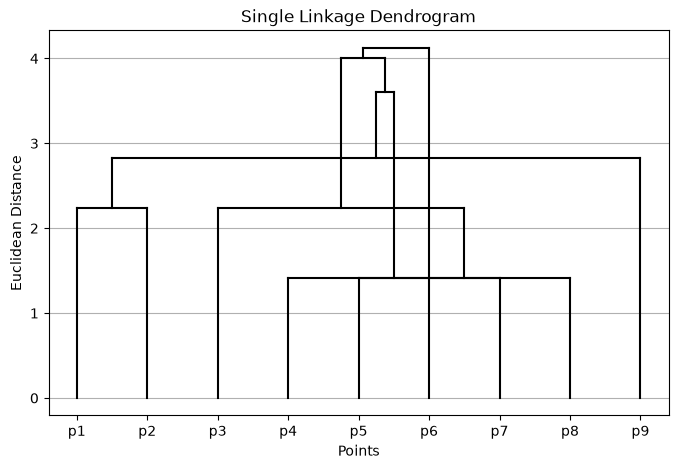


Complete - Iteration 1
Merge: ['p4'] and ['p7']
Distance = 1.414
Updated Proximity Matrix:
          {p1}  {p2}  {p3}  {p5}   {p6}  {p8}  {p9}  {p4,p7}
{p1}      0.00  2.24  8.00  6.08  10.00  7.28  3.00     7.62
{p2}      2.24  0.00  6.08  4.00   7.81  5.10  2.83     6.08
{p3}      8.00  6.08  0.00  2.24   6.00  2.24  8.54     8.60
{p5}      6.08  4.00  2.24  0.00   5.39  1.41  6.32     6.71
{p6}     10.00  7.81  6.00  5.39   0.00  4.12  8.54     6.00
{p8}      7.28  5.10  2.24  1.41   4.12  0.00  7.07     6.40
{p9}      3.00  2.83  8.54  6.32   8.54  7.07  0.00     5.00
{p4,p7}   7.62  6.08  8.60  6.71   6.00  6.40  5.00     0.00

Complete - Iteration 2
Merge: ['p5'] and ['p8']
Distance = 1.414
Updated Proximity Matrix:
          {p1}  {p2}  {p3}   {p6}  {p9}  {p4,p7}  {p5,p8}
{p1}      0.00  2.24  8.00  10.00  3.00     7.62     7.28
{p2}      2.24  0.00  6.08   7.81  2.83     6.08     5.10
{p3}      8.00  6.08  0.00   6.00  8.54     8.60     2.24
{p6}     10.00  7.81  6.00   0.00  

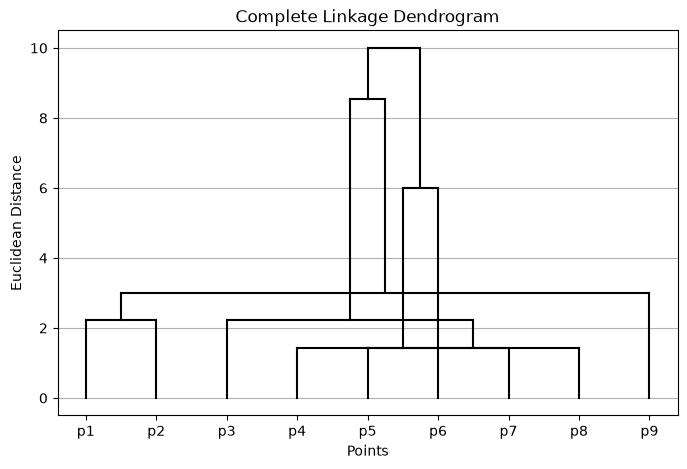


Average - Iteration 1
Merge: ['p4'] and ['p7']
Distance = 1.414
Updated Proximity Matrix:
          {p1}  {p2}  {p3}  {p5}   {p6}  {p8}  {p9}  {p4,p7}
{p1}      0.00  2.24  8.00  6.08  10.00  7.28  3.00     6.97
{p2}      2.24  0.00  6.08  4.00   7.81  5.10  2.83     5.54
{p3}      8.00  6.08  0.00  2.24   6.00  2.24  8.54     8.54
{p5}      6.08  4.00  2.24  0.00   5.39  1.41  6.32     6.56
{p6}     10.00  7.81  6.00  5.39   0.00  4.12  8.54     5.55
{p8}      7.28  5.10  2.24  1.41   4.12  0.00  7.07     6.40
{p9}      3.00  2.83  8.54  6.32   8.54  7.07  0.00     4.30
{p4,p7}   6.97  5.54  8.54  6.56   5.55  6.40  4.30     0.00

Average - Iteration 2
Merge: ['p5'] and ['p8']
Distance = 1.414
Updated Proximity Matrix:
          {p1}  {p2}  {p3}   {p6}  {p9}  {p4,p7}  {p5,p8}
{p1}      0.00  2.24  8.00  10.00  3.00     6.97     6.68
{p2}      2.24  0.00  6.08   7.81  2.83     5.54     4.55
{p3}      8.00  6.08  0.00   6.00  8.54     8.54     2.24
{p6}     10.00  7.81  6.00   0.00  8.

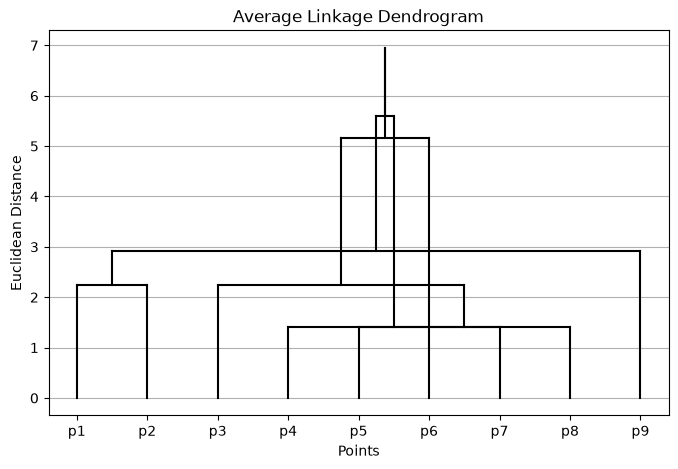

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data
df = pd.DataFrame({
    'Point': ['p1','p2','p3','p4','p5','p6','p7','p8','p9'],
    'X': [1,3,9,3,7,9,4,8,1],
    'Y': [1,2,1,7,2,7,8,3,4]
})

points = df['Point'].values
data = df[['X', 'Y']].values


# a. Scatter plot
plt.scatter(data[:, 0], data[:, 1])

for i, p in enumerate(points):
    plt.text(data[i, 0] + 0.1, data[i, 1] + 0.1, p)



plt.xlabel("X")
plt.ylabel("Y")
plt.title("Scatter Plot")
plt.grid(True)
plt.show()


# Distance between two points
def get_distance(a, b, metric, p=3):
    if metric == 'euclidean':
        return np.sqrt(np.sum((a - b) ** 2))
    elif metric == 'manhattan':
        return np.sum(np.abs(a - b))
    else:
        return np.sum(np.abs(a - b) ** p) ** (1 / p)


# Proximity matrix
def get_distance_matrix(data, metric, p=3):
    n = len(data)
    D = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            D[i, j] = get_distance(data[i], data[j], metric, p)

    return D


# b. Display all proximity matrices
for metric in ['euclidean', 'manhattan', 'minkowski']:
    D = get_distance_matrix(data, metric)
    print(f"\n{metric} Proximity Matrix")
    print(pd.DataFrame(D, index=points, columns=points).round(2))


# c. Hierarchical clustering
def hierarchical_clustering(data, points, method):
    clusters = [[i] for i in range(len(data))]
    merges = []

    heights = {tuple(c): 0 for c in clusters}
    positions = {tuple(c): float(c[0]) for c in clusters}

    def cluster_distance(c1, c2):
        distances = [
            get_distance(data[a], data[b], 'euclidean')
            for a in c1 for b in c2
        ]

        if method == 'single':
            return min(distances)
        elif method == 'complete':
            return max(distances)
        else:
            return np.mean(distances)

    iteration = 1

    while len(clusters) > 1:
        min_dist = float('inf')
        merge_i, merge_j = -1, -1

        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                distance = cluster_distance(clusters[i], clusters[j])

                if distance < min_dist:
                    min_dist = distance
                    merge_i, merge_j = i, j

        c1 = clusters[merge_i]
        c2 = clusters[merge_j]

        print(f"\n{method.capitalize()} - Iteration {iteration}")
        print("Merge:", [points[i] for i in c1],"and", [points[i] for i in c2])
        print("Distance =", round(min_dist, 3))

        merges.append((c1.copy(), c2.copy(), min_dist))

        merged = c1 + c2
        clusters.pop(merge_j)
        clusters.pop(merge_i)
        clusters.append(merged)

        heights[tuple(merged)] = min_dist
        positions[tuple(merged)] = (positions[tuple(c1)] + positions[tuple(c2)]) / 2

        # Updated proximity matrix using Euclidean distance
        n = len(clusters)
        new_D = np.zeros((n, n))

        for i in range(n):
            for j in range(n):
                if i != j:
                    new_D[i, j] = cluster_distance(clusters[i], clusters[j])

        labels = []
        for c in clusters:
            label = ""
            for k in c:
                label += points[k] + ","
            labels.append("{" + label[:-1] + "}")

        print("Updated Proximity Matrix:")
        print(pd.DataFrame(new_D, index=labels, columns=labels).round(2))

        iteration += 1

    # Draw dendrogram manually
    plt.figure(figsize=(8, 5))

    for c1, c2, height in merges:
        x1 = positions[tuple(c1)]
        x2 = positions[tuple(c2)]

        h1 = heights[tuple(c1)]
        h2 = heights[tuple(c2)]

        plt.plot([x1, x1], [h1, height], color='black')
        plt.plot([x2, x2], [h2, height], color='black')
        plt.plot([x1, x2], [height, height], color='black')

    plt.xticks(range(len(points)), points)
    plt.xlabel("Points")
    plt.ylabel("Euclidean Distance")
    plt.title(f"{method.capitalize()} Linkage Dendrogram")
    plt.grid(axis='y')
    plt.show()


for method in ['single', 'complete', 'average']:
    hierarchical_clustering(data, points, method)
